# ML for Healthcare in Nepal: A Comparative Study of Five ML Algorithms
### CSC61304 - Machine Learning and Intelligent Systems
**Dataset:** BRFSS 2015 Health Indicators (proxy for Nepal MoHP healthcare planning)

## Experiments
**Classification (2 algorithms × 2 target views = 4 experiments):**
1. Logistic Regression — Binary
2. Logistic Regression — Multiclass
3. Random Forest — Binary
4. Random Forest — Multiclass

**Regression (2 algorithms on continuous BMI target):**
5. Linear Regression
6. Decision Tree Regressor

**Unsupervised (1 algorithm):**
7. K-Means Clustering

## Concepts Covered
EDA · Missing Value Imputation · Outlier Handling (IQR) · Feature Scaling ·
Variable Transformation (log1p) · Feature Construction · Feature Selection (SelectKBest + Mutual Info) ·
Feature Extraction (PCA) · ColumnTransformer · Pipeline · Imbalanced Data (class_weight) ·
Gradient Descent · Bias–Variance · Overfitting · Underfitting · L1 (Lasso) · L2 (Ridge) ·
Ensemble Learning · Bagging · ROC · AUC · Hyperparameter Tuning · Clustering Validation

In [1]:
import pandas as pd
import numpy as np
import warnings, os, joblib
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    f1_score, precision_score, recall_score, accuracy_score,
    ConfusionMatrixDisplay, silhouette_score, calinski_harabasz_score,
    davies_bouldin_score, mean_squared_error, mean_absolute_error, r2_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
os.makedirs("artifacts", exist_ok=True)
os.makedirs("plots", exist_ok=True)

In [2]:
df = pd.read_csv("/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_012_health_indicators_BRFSS2015.csv")

In [4]:
df.sample(5)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
219620,0.0,0.0,0.0,1.0,21.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,3.0,7.0,0.0,0.0,7.0,4.0,2.0
132821,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,13.0,6.0,6.0
151862,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,4.0,7.0
139717,0.0,0.0,0.0,1.0,27.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,3.0,0.0,0.0,1.0,2.0,4.0,7.0
239235,0.0,0.0,1.0,1.0,31.0,1.0,0.0,0.0,0.0,1.0,...,1.0,1.0,4.0,27.0,27.0,1.0,0.0,8.0,3.0,2.0


In [5]:
df.sample(5)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
109394,0.0,0.0,1.0,1.0,27.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,9.0,6.0,8.0
106676,0.0,0.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,6.0,6.0,8.0
11973,0.0,1.0,1.0,1.0,26.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,10.0,6.0,8.0
33652,1.0,0.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,3.0,0.0,0.0,0.0,1.0,7.0,3.0,7.0
196546,0.0,0.0,0.0,1.0,26.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0


In [4]:
df.info()
print("\nClass distribution (Diabetes_012):")
print(df['Diabetes_012'].value_counts())
print("\nPercentage:")
print((df['Diabetes_012'].value_counts(normalize=True) * 100).round(2))
print("\nBMI summary:")
print(df['BMI'].describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [8]:
!pip install ydata-profiling

In [9]:
from ydata_profiling import ProfileReport

prof = ProfileReport(df, title="Summary EDA")
prof.to_file("SummaryEDA.html")


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 22/22 [00:05<00:00,  3.96it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

## Cell 6 — Markdown: Cleaning
## 2. Data Cleaning
- Drop duplicates
- Remove impossible BMI (<= 0)
- **Outlier handling (IQR capping)** on BMI, MentHlth, PhysHlth

In [5]:
##Cell 7 — Dedup & BMI Filter
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After dedup:", df.shape)

df = df[df['BMI'] > 0].reset_index(drop=True)
print("After BMI filter:", df.shape)

Before: (253680, 22)
After dedup: (229781, 22)
After BMI filter: (229781, 22)


In [6]:
##Cell 8 — Outlier Handling (IQR Capping)
def iqr_cap(series, factor=1.5):
    """Cap values outside [Q1 - factor*IQR, Q3 + factor*IQR]."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - factor * iqr, q3 + factor * iqr
    return series.clip(lower, upper)

outlier_cols = ['BMI', 'MentHlth', 'PhysHlth']

print("Before outlier capping:")
print(df[outlier_cols].describe().round(2))

for col in outlier_cols:
    df[col] = iqr_cap(df[col])

print("\nAfter outlier capping:")
print(df[outlier_cols].describe().round(2))

Before outlier capping:
             BMI   MentHlth   PhysHlth
count  229781.00  229781.00  229781.00
mean       28.69       3.51       4.68
std         6.79       7.71       9.05
min        12.00       0.00       0.00
25%        24.00       0.00       0.00
50%        27.00       0.00       0.00
75%        32.00       2.00       4.00
max        98.00      30.00      30.00

After outlier capping:
             BMI   MentHlth   PhysHlth
count  229781.00  229781.00  229781.00
mean       28.47       1.29       2.47
std         5.88       2.01       3.81
min        12.00       0.00       0.00
25%        24.00       0.00       0.00
50%        27.00       0.00       0.00
75%        32.00       2.00       4.00
max        44.00       5.00      10.00


## 3. Exploratory Data Analysis

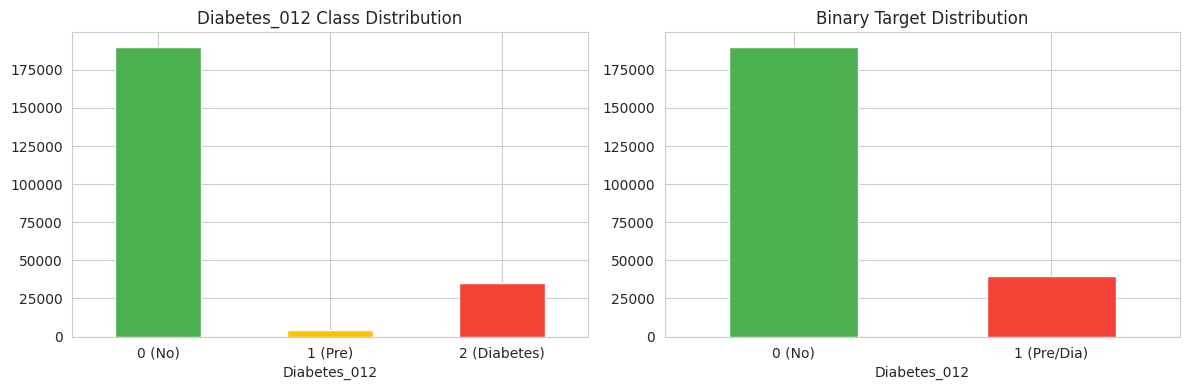

In [7]:
##Cell 10 — Class Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Diabetes_012'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color=['#4CAF50', '#FFC107', '#F44336'])
axes[0].set_title("Diabetes_012 Class Distribution")
axes[0].set_xticklabels(['0 (No)', '1 (Pre)', '2 (Diabetes)'], rotation=0)

binary_counts = df['Diabetes_012'].apply(lambda x: 0 if x == 0 else 1).value_counts()
binary_counts.plot(kind='bar', ax=axes[1], color=['#4CAF50', '#F44336'])
axes[1].set_title("Binary Target Distribution")
axes[1].set_xticklabels(['0 (No)', '1 (Pre/Dia)'], rotation=0)

plt.tight_layout()
plt.savefig("plots/class_distribution.png", dpi=120)
plt.show()

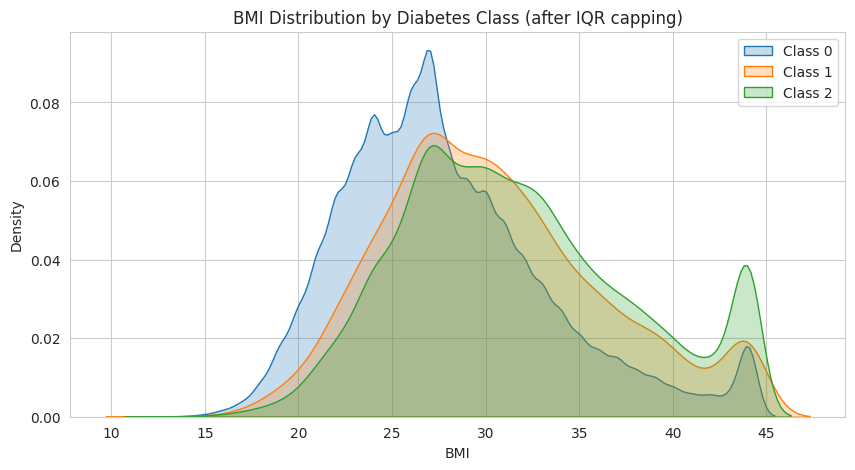

In [8]:
##Cell 11 — BMI vs Class (Post Outlier Handling)
plt.figure(figsize=(10, 5))
for cls in sorted(df['Diabetes_012'].unique()):
    sns.kdeplot(df[df['Diabetes_012'] == cls]['BMI'],
                label=f"Class {int(cls)}", fill=True)
plt.title("BMI Distribution by Diabetes Class (after IQR capping)")
plt.xlabel("BMI")
plt.legend()
plt.savefig("plots/bmi_by_class.png", dpi=120)
plt.show()

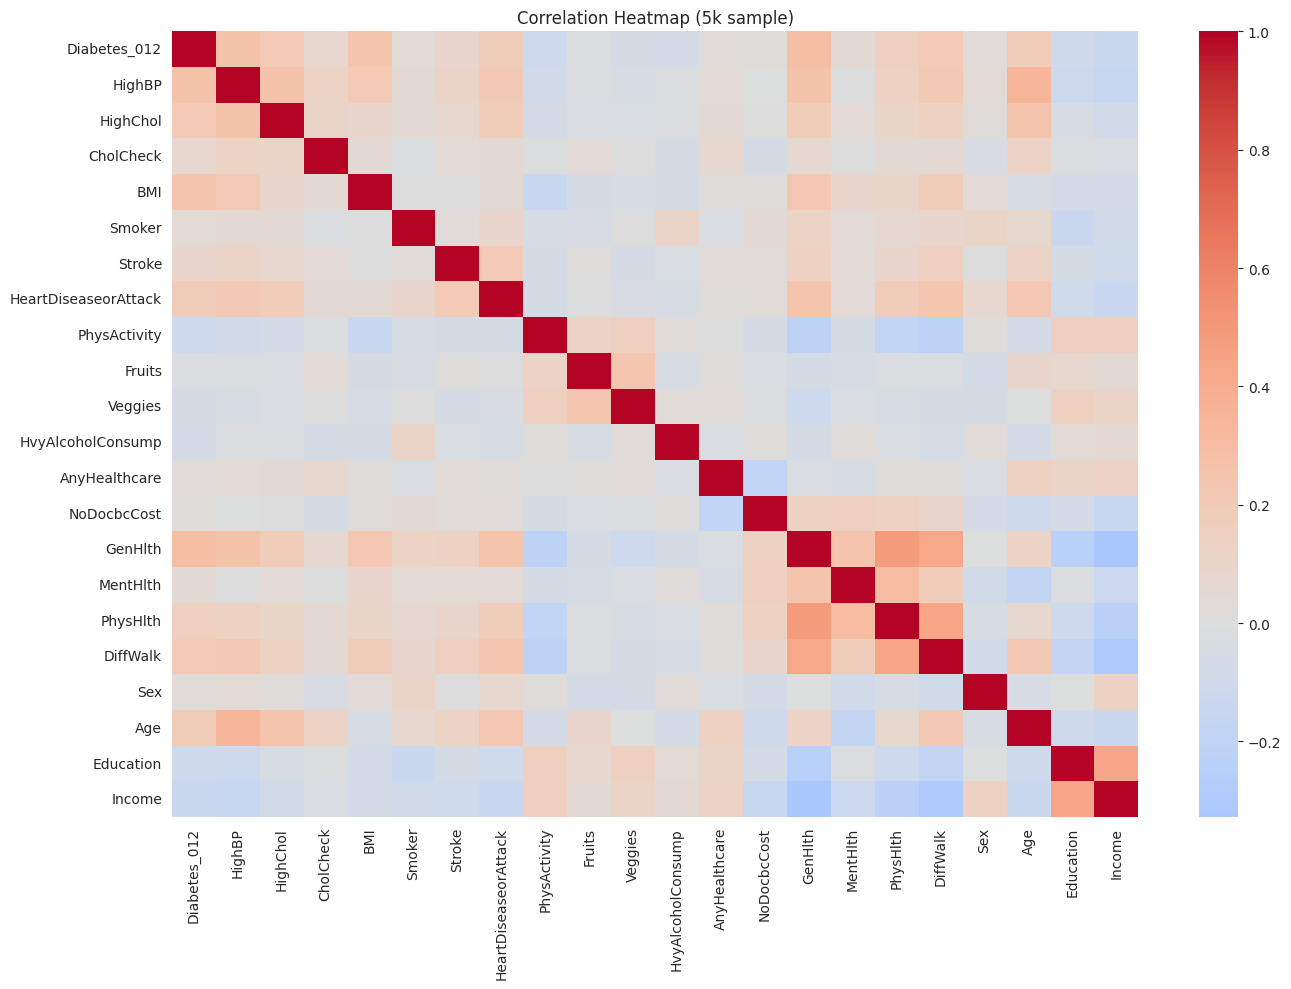

In [9]:
##Cell 12 — Correlation Heatmap
sample = df.sample(n=5000, random_state=RANDOM_STATE)
plt.figure(figsize=(14, 10))
sns.heatmap(sample.corr(), cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Heatmap (5k sample)")
plt.tight_layout()
plt.savefig("plots/correlation.png", dpi=120)
plt.show()

In [10]:
##Cell 13 — Skewness Check (Motivates log1p)
print("Skewness BEFORE transformation:")
print(df[['MentHlth','PhysHlth','BMI']].skew().round(3))

Skewness BEFORE transformation:
MentHlth    1.118
PhysHlth    1.240
BMI         0.713
dtype: float64


## 4. Feature Construction

We create **domain-driven features** grounded in clinical reasoning:

| Feature | Formula | Rationale |
|---|---|---|
| `Chronic_count` | HighBP + HighChol + Stroke + HeartDiseaseorAttack | Comorbidity burden |
| `Lifestyle_score` | PhysActivity + Fruits + Veggies − HvyAlcoholConsump | Healthy behavior index |
| `BMI_x_Age` | BMI × Age | Obesity impacts more with age |
| `GenHlth_x_Age` | GenHlth × Age | Health decline accelerates with age |
| `DiffWalk_x_Age` | DiffWalk × Age | Mobility risk compounds with age |

In [11]:
#Cell 15 — Construct Features
df['Chronic_count']   = (df['HighBP'] + df['HighChol'] +
                         df['Stroke'] + df['HeartDiseaseorAttack'])
df['Lifestyle_score'] = (df['PhysActivity'] + df['Fruits'] +
                         df['Veggies'] - df['HvyAlcoholConsump'])
df['BMI_x_Age']       = df['BMI'] * df['Age']
df['GenHlth_x_Age']   = df['GenHlth'] * df['Age']
df['DiffWalk_x_Age']  = df['DiffWalk'] * df['Age']

engineered_cols = ['Chronic_count', 'Lifestyle_score',
                   'BMI_x_Age', 'GenHlth_x_Age', 'DiffWalk_x_Age']

print("Engineered features added:")
print(df[engineered_cols].describe().round(2))

Engineered features added:
       Chronic_count  Lifestyle_score  BMI_x_Age  GenHlth_x_Age  \
count      229781.00        229781.00  229781.00      229781.00   
mean            1.04             2.08     229.42          21.51   
std             0.98             0.92      96.53          12.92   
min             0.00            -1.00      14.00           1.00   
25%             0.00             1.00     162.00          11.00   
50%             1.00             2.00     232.00          20.00   
75%             2.00             3.00     297.00          30.00   
max             4.00             3.00     572.00          65.00   

       DiffWalk_x_Age  
count       229781.00  
mean             1.75  
std              3.82  
min              0.00  
25%              0.00  
50%              0.00  
75%              0.00  
max             13.00  


## 5. Feature Groups & Targets

**Three targets:**
- `Diabetes_binary` → Classification (LogReg, RF)
- `Diabetes_012`    → Classification (multiclass extension)
- `BMI`             → Regression (Linear Regression, Decision Tree)

In [12]:
#Cell 17 — Column Groups & Targets
binary_cols = ['HighBP','HighChol','CholCheck','Smoker','Stroke',
               'HeartDiseaseorAttack','PhysActivity','Fruits','Veggies',
               'HvyAlcoholConsump','AnyHealthcare','NoDocbcCost',
               'DiffWalk','Sex']

ordinal_cols = ['GenHlth','Age','Education','Income']

# numeric_cols includes the engineered features
numeric_cols = ['BMI','MentHlth','PhysHlth'] + engineered_cols

# Binary target
df['Diabetes_binary'] = (df['Diabetes_012'] > 0).astype(int)

X_cls   = df.drop(columns=['Diabetes_012', 'Diabetes_binary'])
y_bin   = df['Diabetes_binary']
y_multi = df['Diabetes_012'].astype(int)

# Regression: BMI is TARGET, so remove it and BMI_x_Age (leaks BMI)
X_reg = df.drop(columns=['BMI', 'BMI_x_Age'])
y_reg = df['BMI']

# Regression feature groups
numeric_cols_reg = ['MentHlth','PhysHlth','Chronic_count',
                    'Lifestyle_score','GenHlth_x_Age','DiffWalk_x_Age']
binary_cols_reg  = binary_cols + ['Diabetes_012']
ordinal_cols_reg = ordinal_cols

print("Classification features:", X_cls.shape)
print("Regression features:", X_reg.shape)

Classification features: (229781, 26)
Regression features: (229781, 26)


## Cell 18 — Markdown: Splits
## 6. Train/Test Splits

In [13]:
X_train, X_test, yb_train, yb_test = train_test_split(
    X_cls, y_bin, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin)
_, _, ym_train, ym_test = train_test_split(
    X_cls, y_multi, test_size=0.2, random_state=RANDOM_STATE, stratify=y_multi)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

print("Binary:", yb_train.shape, yb_test.shape)
print("Multiclass:", ym_train.shape, ym_test.shape)
print("Regression:", yr_train.shape, yr_test.shape)

Binary: (183824,) (45957,)
Multiclass: (183824,) (45957,)
Regression: (183824,) (45957,)


## Cell 20 — Markdown: Preprocessors
## 7. Preprocessing Pipelines
- Missing value imputation
- **Variable transformation:** `log1p` on skewed count features (`MentHlth`, `PhysHlth`)
- Standard scaling
- ColumnTransformer wraps everything

## Cell 21 — Preprocessor Builder (Classification)

In [14]:
log_cols = ['MentHlth', 'PhysHlth']

def build_preprocessor_cls(use_feature_selection=False, k=15):
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ])
    bin_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
    ])
    ord_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ])
    ct = ColumnTransformer([
        ('num', num_pipe, numeric_cols),
        ('bin', bin_pipe, binary_cols),
        ('ord', ord_pipe, ordinal_cols),
    ])
    if use_feature_selection:
        return Pipeline([
            ('ct', ct),
            ('select', SelectKBest(score_func=mutual_info_classif, k=k)),
        ])
    return ct

def build_preprocessor_reg():
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ])
    bin_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
    ])
    ord_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ])
    return ColumnTransformer([
        ('num', num_pipe, numeric_cols_reg),
        ('bin', bin_pipe, binary_cols_reg),
        ('ord', ord_pipe, ordinal_cols_reg),
    ])

build_preprocessor_cls()

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['BMI', 'MentHlth', 'PhysHlth',
                                  'Chronic_count', 'Lifestyle_score',
                                  'BMI_x_Age', 'GenHlth_x_Age',
                                  'DiffWalk_x_Age']),
                                ('bin',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent'))]),
                                 ['HighBP', 'HighChol', 'CholCheck', 'Smoker',
                                  'Stroke', 'HeartDiseaseorAttack',
                                  'PhysActivity', 'Fruits', 'Veggies',
                                  'HvyAlcoholConsump', 'AnyHealthcare',
                                  'NoDocbcCost', 'DiffWalk', 'Sex']),
                                ('ord',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['GenHlth', 'Age', 'Education', 'Income'])])

Cell 22 — Markdown: Feature Selection Demo
## 8. Feature Selection Demo (SelectKBest + Mutual Information)
Applied as an optional layer inside the classification pipeline.

In [15]:
# Cell 23 — Feature Selection (Standalone Demo)
fs_pipe = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('select', SelectKBest(score_func=mutual_info_classif, k=15)),
])
fs_pipe.fit(X_train, yb_train)

feature_names = fs_pipe.named_steps['prep'].get_feature_names_out()
scores = fs_pipe.named_steps['select'].scores_
mask = fs_pipe.named_steps['select'].get_support()

fs_df = pd.DataFrame({
    'Feature': feature_names, 'MI Score': scores, 'Selected': mask
}).sort_values('MI Score', ascending=False).round(5)
print(fs_df)
fs_df.to_csv("artifacts/feature_selection_scores.csv", index=False)

                      Feature  MI Score  Selected
6          num__GenHlth_x_Age   0.05734      True
3          num__Chronic_count   0.05519      True
5              num__BMI_x_Age   0.05066      True
8                 bin__HighBP   0.04780      True
22               ord__GenHlth   0.04612      True
18         bin__AnyHealthcare   0.03806      True
10             bin__CholCheck   0.03779      True
9               bin__HighChol   0.03483      True
14          bin__PhysActivity   0.03381      True
16               bin__Veggies   0.02946      True
7         num__DiffWalk_x_Age   0.02811      True
0                    num__BMI   0.02781      True
15                bin__Fruits   0.02704      True
23                   ord__Age   0.02339      True
2               num__PhysHlth   0.02203      True
20              bin__DiffWalk   0.02109     False
11                bin__Smoker   0.01899     False
21                   bin__Sex   0.01787     False
25                ord__Income   0.01778     False


## ALGORITHM 1 & 2 — LOGISTIC REGRESSION****

## 9. Algorithm 1 & 2 — Logistic Regression (Binary + Multiclass)

**Optimization:** Logistic Regression minimizes **Binary Cross-Entropy** loss using
**Gradient Descent**:

    L(θ) = −(1/n) Σ [ yᵢ log(hθ(xᵢ)) + (1−yᵢ) log(1−hθ(xᵢ)) ]

where `hθ(x) = σ(θᵀx)` is the sigmoid. Update rule:
    θ ← θ − α ∇L(θ)

**Regularization:**
- L2 (Ridge): adds λ‖θ‖² to loss → shrinks coefficients, keeps all features.
- L1 (Lasso): adds λ‖θ‖₁ → produces sparse solutions (feature selection).
- ElasticNet: combines both.

In [16]:
# Cell 25 — LogReg Binary Baseline
logreg_bin = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000,
                               random_state=RANDOM_STATE, n_jobs=-1))
])
logreg_bin.fit(X_train, yb_train)

yb_pred_lr = logreg_bin.predict(X_test)
yb_prob_lr = logreg_bin.predict_proba(X_test)[:, 1]

print("=== LogReg BINARY (baseline) ===")
print(classification_report(yb_test, yb_pred_lr, digits=3))
print("ROC-AUC:", round(roc_auc_score(yb_test, yb_prob_lr), 4))

=== LogReg BINARY (baseline) ===
              precision    recall  f1-score   support

           0      0.933     0.712     0.808     38012
           1      0.354     0.754     0.481      7945

    accuracy                          0.719     45957
   macro avg      0.643     0.733     0.645     45957
weighted avg      0.832     0.719     0.751     45957

ROC-AUC: 0.8089


In [17]:
# Cell 26 — LogReg Multiclass Baseline
logreg_multi = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('clf', LogisticRegression(multi_class='multinomial',
                               class_weight='balanced', max_iter=1000,
                               random_state=RANDOM_STATE, n_jobs=-1))
])
logreg_multi.fit(X_train, ym_train)

ym_pred_lr = logreg_multi.predict(X_test)
ym_prob_lr = logreg_multi.predict_proba(X_test)

print("=== LogReg MULTICLASS (baseline) ===")
print(classification_report(ym_test, ym_pred_lr, digits=3))
print("F1-macro:", round(f1_score(ym_test, ym_pred_lr, average='macro'), 4))
print("ROC-AUC (OVR macro):",
      round(roc_auc_score(ym_test, ym_prob_lr, multi_class='ovr', average='macro'), 4))

=== LogReg MULTICLASS (baseline) ===
              precision    recall  f1-score   support

           0      0.834     0.225     0.355     38012
           1      0.021     0.436     0.040       926
           2      0.154     0.359     0.216      7019

    accuracy                          0.250     45957
   macro avg      0.336     0.340     0.204     45957
weighted avg      0.714     0.250     0.327     45957

F1-macro: 0.2035
ROC-AUC (OVR macro): 0.5075


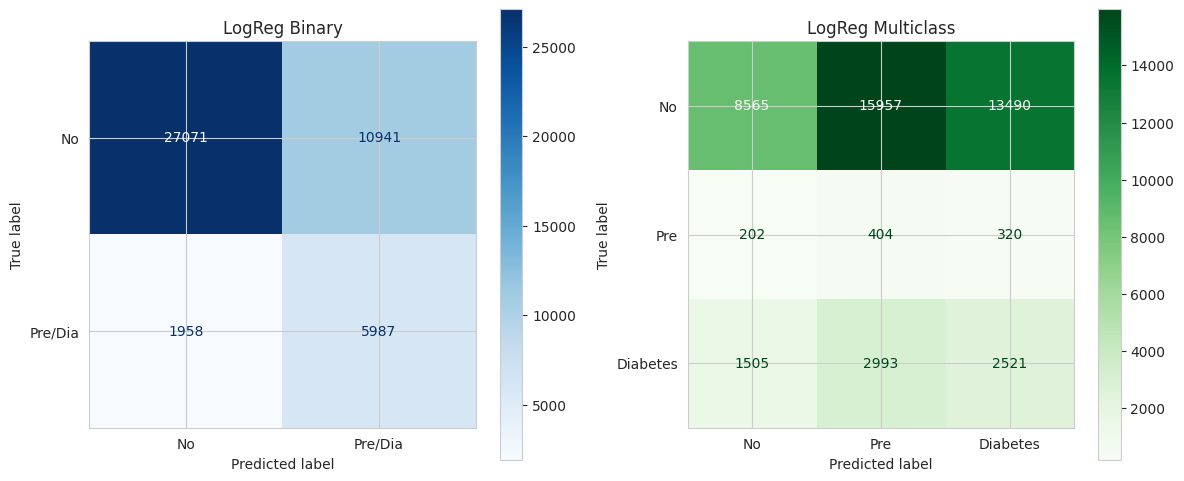

In [18]:
# Cell 27 — Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(yb_test, yb_pred_lr, ax=axes[0],
                                        cmap='Blues', display_labels=['No','Pre/Dia'])
axes[0].set_title("LogReg Binary")
ConfusionMatrixDisplay.from_predictions(ym_test, ym_pred_lr, ax=axes[1],
                                        cmap='Greens', display_labels=['No','Pre','Diabetes'])
axes[1].set_title("LogReg Multiclass")
plt.tight_layout()
plt.savefig("plots/logreg_cm.png", dpi=120)
plt.show()

In [20]:
# Cell 28 — Tune LogReg
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

param_grid_lr = {'clf__C': [0.01, 0.1, 1.0, 10.0],
                 'clf__solver': ['lbfgs', 'saga']}

grid_lr_bin = GridSearchCV(
    Pipeline([('prep', build_preprocessor_cls()),
              ('clf', LogisticRegression(class_weight='balanced', max_iter=1000,
                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid=param_grid_lr, scoring='roc_auc', cv=cv, n_jobs=-1)
grid_lr_bin.fit(X_train, yb_train)
print("Best LR Binary:", grid_lr_bin.best_params_,
      "| AUC:", round(grid_lr_bin.best_score_, 4))

grid_lr_multi = GridSearchCV(
    Pipeline([('prep', build_preprocessor_cls()),
              ('clf', LogisticRegression(multi_class='multinomial',
                                         class_weight='balanced', max_iter=1000,
                                         random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid=param_grid_lr, scoring='f1_macro', cv=cv, n_jobs=-1)
grid_lr_multi.fit(X_train, ym_train)
print("Best LR Multi :", grid_lr_multi.best_params_,
      "| F1-macro:", round(grid_lr_multi.best_score_, 4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Best LR Binary: {'clf__C': 0.01, 'clf__solver': 'lbfgs'} | AUC: 0.805


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

Best LR Multi : {'clf__C': 10.0, 'clf__solver': 'saga'} | F1-macro: 0.2318


In [21]:
# Cell 29 — Evaluate Tuned LogReg
best_lr_bin   = grid_lr_bin.best_estimator_
best_lr_multi = grid_lr_multi.best_estimator_

yb_pred_lr_t = best_lr_bin.predict(X_test)
yb_prob_lr_t = best_lr_bin.predict_proba(X_test)[:, 1]

ym_pred_lr_t = best_lr_multi.predict(X_test)
ym_prob_lr_t = best_lr_multi.predict_proba(X_test)

print("=== Tuned LogReg BINARY ===")
print(classification_report(yb_test, yb_pred_lr_t, digits=3))
print("ROC-AUC:", round(roc_auc_score(yb_test, yb_prob_lr_t), 4))

print("\n=== Tuned LogReg MULTICLASS ===")
print(classification_report(ym_test, ym_pred_lr_t, digits=3))
print("F1-macro:", round(f1_score(ym_test, ym_pred_lr_t, average='macro'), 4))

=== Tuned LogReg BINARY ===
              precision    recall  f1-score   support

           0      0.933     0.714     0.809     38012
           1      0.355     0.753     0.483      7945

    accuracy                          0.721     45957
   macro avg      0.644     0.734     0.646     45957
weighted avg      0.833     0.721     0.752     45957

ROC-AUC: 0.809

=== Tuned LogReg MULTICLASS ===
              precision    recall  f1-score   support

           0      0.827     0.136     0.233     38012
           1      0.019     0.355     0.037       926
           2      0.152     0.489     0.232      7019

    accuracy                          0.194     45957
   macro avg      0.333     0.327     0.167     45957
weighted avg      0.708     0.194     0.229     45957

F1-macro: 0.167


Cell 30 — Markdown: Ridge vs Lasso Side-Experiment
## 10. Regularization Side-Experiment — Ridge (L2) vs Lasso (L1)

Same pipeline, swap the penalty to see the effect on Binary LogReg.
This demonstrates **regularization** as a concept.

In [22]:
# Cell 31 — Ridge (L2)
ridge_bin = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('clf', LogisticRegression(penalty='l2', C=1.0, solver='saga',
                               class_weight='balanced', max_iter=2000,
                               random_state=RANDOM_STATE))
])
ridge_bin.fit(X_train, yb_train)
yb_pred_ridge = ridge_bin.predict(X_test)
yb_prob_ridge = ridge_bin.predict_proba(X_test)[:, 1]

print("=== Ridge (L2) LogReg Binary ===")
print(classification_report(yb_test, yb_pred_ridge, digits=3))
print("ROC-AUC:", round(roc_auc_score(yb_test, yb_prob_ridge), 4))

=== Ridge (L2) LogReg Binary ===
              precision    recall  f1-score   support

           0      0.933     0.712     0.808     38012
           1      0.354     0.754     0.482      7945

    accuracy                          0.719     45957
   macro avg      0.643     0.733     0.645     45957
weighted avg      0.833     0.719     0.751     45957

ROC-AUC: 0.8089


In [23]:
# Cell 32 — Lasso (L1)
lasso_bin = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('clf', LogisticRegression(penalty='l1', C=1.0, solver='saga',
                               class_weight='balanced', max_iter=2000,
                               random_state=RANDOM_STATE))
])
lasso_bin.fit(X_train, yb_train)
yb_pred_lasso = lasso_bin.predict(X_test)
yb_prob_lasso = lasso_bin.predict_proba(X_test)[:, 1]

print("=== Lasso (L1) LogReg Binary ===")
print(classification_report(yb_test, yb_pred_lasso, digits=3))
print("ROC-AUC:", round(roc_auc_score(yb_test, yb_prob_lasso), 4))

# Show sparsity effect
coefs = lasso_bin.named_steps['clf'].coef_[0]
n_zero = (coefs == 0).sum()
print(f"\nLasso zeroed out {n_zero} / {len(coefs)} coefficients")

=== Lasso (L1) LogReg Binary ===
              precision    recall  f1-score   support

           0      0.933     0.712     0.808     38012
           1      0.354     0.754     0.482      7945

    accuracy                          0.719     45957
   macro avg      0.643     0.733     0.645     45957
weighted avg      0.833     0.719     0.751     45957

ROC-AUC: 0.8089

Lasso zeroed out 2 / 26 coefficients


In [24]:
# Cell 33 — Regularization Comparison
reg_compare = pd.DataFrame([
    {'Penalty': 'None (default)', 'ROC-AUC': roc_auc_score(yb_test, yb_prob_lr)},
    {'Penalty': 'L2 (Ridge)',     'ROC-AUC': roc_auc_score(yb_test, yb_prob_ridge)},
    {'Penalty': 'L1 (Lasso)',     'ROC-AUC': roc_auc_score(yb_test, yb_prob_lasso)},
]).round(4)
print(reg_compare)
reg_compare.to_csv("artifacts/regularization_comparison.csv", index=False)

          Penalty  ROC-AUC
0  None (default)   0.8089
1      L2 (Ridge)   0.8089
2      L1 (Lasso)   0.8089


## ALGORITHM 3 & 4 — RANDOM FOREST

## 11. Algorithm 3 & 4 — Random Forest (Binary + Multiclass)

**Ensemble Learning:** RF is a **bagging** ensemble — it trains many decision trees on
bootstrapped samples and averages their votes.

**Bias–Variance:** Bagging reduces **variance** without increasing **bias** —
the reason RF usually beats a single tree.

In [25]:
# Cell 35 — RF Binary Baseline
rf_bin = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('clf', RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                    random_state=RANDOM_STATE, n_jobs=-1))
])
rf_bin.fit(X_train, yb_train)

yb_pred_rf = rf_bin.predict(X_test)
yb_prob_rf = rf_bin.predict_proba(X_test)[:, 1]

print("=== RF BINARY (baseline) ===")
print(classification_report(yb_test, yb_pred_rf, digits=3))
print("ROC-AUC:", round(roc_auc_score(yb_test, yb_prob_rf), 4))

=== RF BINARY (baseline) ===
              precision    recall  f1-score   support

           0      0.850     0.955     0.899     38012
           1      0.471     0.192     0.273      7945

    accuracy                          0.823     45957
   macro avg      0.660     0.573     0.586     45957
weighted avg      0.784     0.823     0.791     45957

ROC-AUC: 0.7695


In [26]:
# Cell 36 — RF Multiclass Baseline
rf_multi = Pipeline([
    ('prep', build_preprocessor_cls()),
    ('clf', RandomForestClassifier(n_estimators=200,
                                    class_weight='balanced_subsample',
                                    random_state=RANDOM_STATE, n_jobs=-1))
])
rf_multi.fit(X_train, ym_train)

ym_pred_rf = rf_multi.predict(X_test)
ym_prob_rf = rf_multi.predict_proba(X_test)

print("=== RF MULTICLASS (baseline) ===")
print(classification_report(ym_test, ym_pred_rf, digits=3))
print("F1-macro:", round(f1_score(ym_test, ym_pred_rf, average='macro'), 4))
print("ROC-AUC (OVR macro):",
      round(roc_auc_score(ym_test, ym_prob_rf, multi_class='ovr', average='macro'), 4))

=== RF MULTICLASS (baseline) ===
              precision    recall  f1-score   support

           0      0.827     0.993     0.903     38012
           1      0.000     0.000     0.000       926
           2      0.179     0.008     0.014      7019

    accuracy                          0.823     45957
   macro avg      0.335     0.334     0.306     45957
weighted avg      0.712     0.823     0.749     45957

F1-macro: 0.3058
ROC-AUC (OVR macro): 0.4966


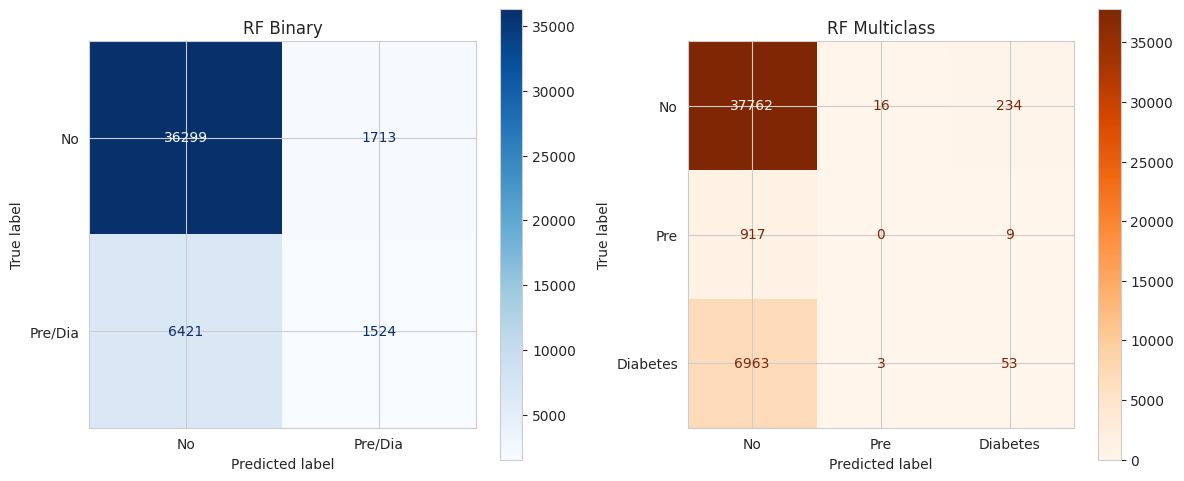

In [27]:
# Cell 37 — RF Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(yb_test, yb_pred_rf, ax=axes[0],
                                        cmap='Blues', display_labels=['No','Pre/Dia'])
axes[0].set_title("RF Binary")
ConfusionMatrixDisplay.from_predictions(ym_test, ym_pred_rf, ax=axes[1],
                                        cmap='Oranges', display_labels=['No','Pre','Diabetes'])
axes[1].set_title("RF Multiclass")
plt.tight_layout()
plt.savefig("plots/rf_cm.png", dpi=120)
plt.show()

In [28]:
# Cell 38 — Tune RF
param_grid_rf = {'clf__n_estimators': [100, 200],
                 'clf__max_depth': [None, 10, 20],
                 'clf__min_samples_leaf': [1, 5, 10]}

grid_rf_bin = GridSearchCV(
    Pipeline([('prep', build_preprocessor_cls()),
              ('clf', RandomForestClassifier(class_weight='balanced',
                                              random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid=param_grid_rf, scoring='roc_auc', cv=cv, n_jobs=-1)
grid_rf_bin.fit(X_train, yb_train)
print("Best RF Binary:", grid_rf_bin.best_params_,
      "| AUC:", round(grid_rf_bin.best_score_, 4))

grid_rf_multi = GridSearchCV(
    Pipeline([('prep', build_preprocessor_cls()),
              ('clf', RandomForestClassifier(class_weight='balanced_subsample',
                                              random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid=param_grid_rf, scoring='f1_macro', cv=cv, n_jobs=-1)
grid_rf_multi.fit(X_train, ym_train)
print("Best RF Multi :", grid_rf_multi.best_params_,
      "| F1-macro:", round(grid_rf_multi.best_score_, 4))

Best RF Binary: {'clf__max_depth': 10, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 200} | AUC: 0.8065
Best RF Multi : {'clf__max_depth': 20, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 100} | F1-macro: 0.3322


In [29]:
#Cell 39 — Evaluate Tuned RF
best_rf_bin   = grid_rf_bin.best_estimator_
best_rf_multi = grid_rf_multi.best_estimator_

yb_pred_rf_t = best_rf_bin.predict(X_test)
yb_prob_rf_t = best_rf_bin.predict_proba(X_test)[:, 1]

ym_pred_rf_t = best_rf_multi.predict(X_test)
ym_prob_rf_t = best_rf_multi.predict_proba(X_test)

print("=== Tuned RF BINARY ===")
print(classification_report(yb_test, yb_pred_rf_t, digits=3))
print("ROC-AUC:", round(roc_auc_score(yb_test, yb_prob_rf_t), 4))

print("\n=== Tuned RF MULTICLASS ===")
print(classification_report(ym_test, ym_pred_rf_t, digits=3))
print("F1-macro:", round(f1_score(ym_test, ym_pred_rf_t, average='macro'), 4))

=== Tuned RF BINARY ===
              precision    recall  f1-score   support

           0      0.933     0.708     0.806     38012
           1      0.352     0.758     0.481      7945

    accuracy                          0.717     45957
   macro avg      0.643     0.733     0.643     45957
weighted avg      0.833     0.717     0.749     45957

ROC-AUC: 0.8108

=== Tuned RF MULTICLASS ===
              precision    recall  f1-score   support

           0      0.828     0.875     0.851     38012
           1      0.014     0.009     0.011       926
           2      0.163     0.122     0.139      7019

    accuracy                          0.742     45957
   macro avg      0.335     0.335     0.334     45957
weighted avg      0.710     0.742     0.725     45957

F1-macro: 0.3336


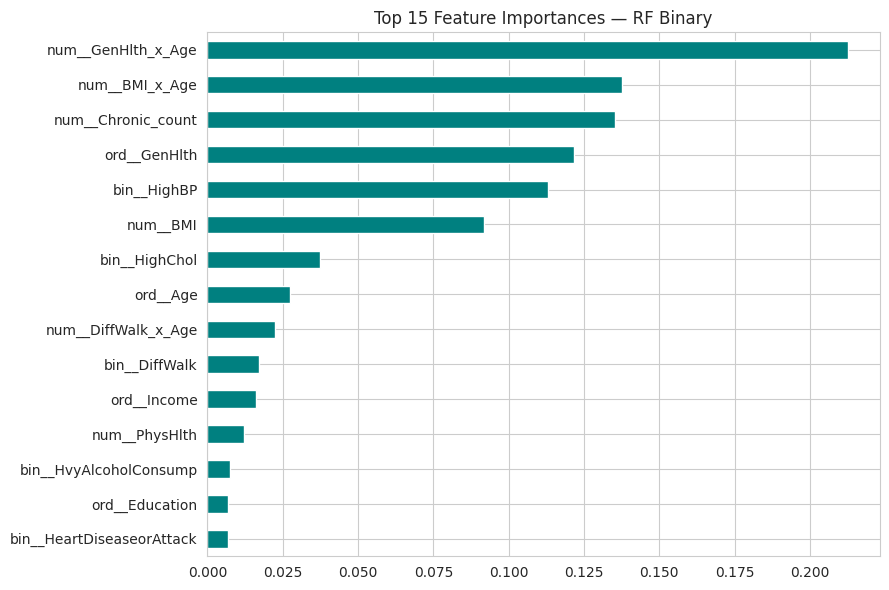

In [30]:
#Cell 40 — RF Feature Importances (Binary)
prep_fi = best_rf_bin.named_steps['prep']
feat_names = prep_fi.get_feature_names_out()
importances = best_rf_bin.named_steps['clf'].feature_importances_
fi = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
fi.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title("Top 15 Feature Importances — RF Binary")
plt.tight_layout()
plt.savefig("plots/rf_feature_importance.png", dpi=120)
plt.show()

## ALGORITHM 5 — LINEAR REGRESSION (BMI)

## 12. Algorithm 5 — Linear Regression (Target = BMI)

**Optimization:** OLS closed-form solution:

    θ = (XᵀX)⁻¹ Xᵀy

For large data, **Gradient Descent** iteratively minimizes MSE:

    θ ← θ − α (2/n) Xᵀ(Xθ − y)

**Bias–Variance:** High bias (linear assumption), low variance.
Linear Regression underfits complex data — the "opposite" of a deep Decision Tree.

In [31]:
# Cell 42 — Linear Regression Baseline
linreg = Pipeline([('prep', build_preprocessor_reg()),
                   ('reg',  LinearRegression())])
linreg.fit(Xr_train, yr_train)

yr_pred_lr = linreg.predict(Xr_test)

rmse_lr = np.sqrt(mean_squared_error(yr_test, yr_pred_lr))
mae_lr  = mean_absolute_error(yr_test, yr_pred_lr)
r2_lr   = r2_score(yr_test, yr_pred_lr)

print("=== Linear Regression (baseline) ===")
print(f"RMSE: {rmse_lr:.4f}\nMAE : {mae_lr:.4f}\nR²  : {r2_lr:.4f}")

=== Linear Regression (baseline) ===
RMSE: 5.3917
MAE : 4.2076
R²  : 0.1519


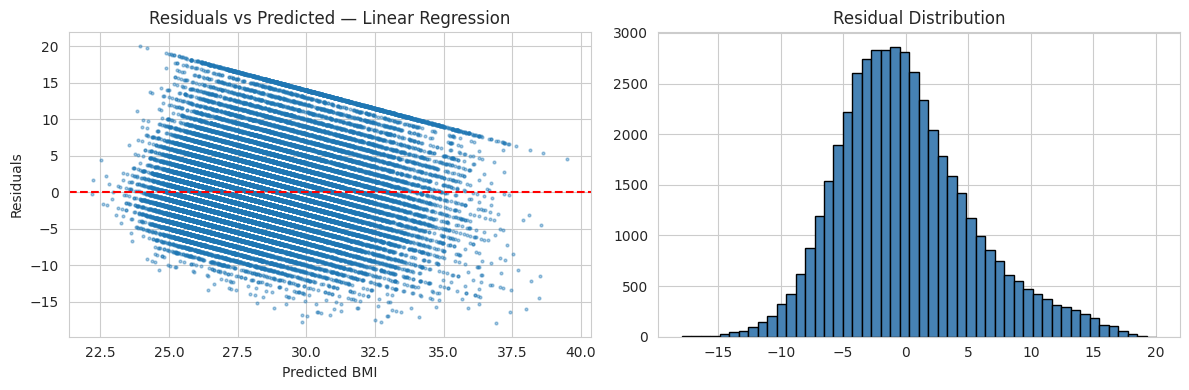

In [32]:
# Cell 43 — Residual Plot
residuals = yr_test - yr_pred_lr
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(yr_pred_lr, residuals, s=4, alpha=0.4)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted BMI"); axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted — Linear Regression")
axes[1].hist(residuals, bins=50, color='steelblue', edgecolor='black')
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.savefig("plots/linreg_residuals.png", dpi=120)
plt.show()

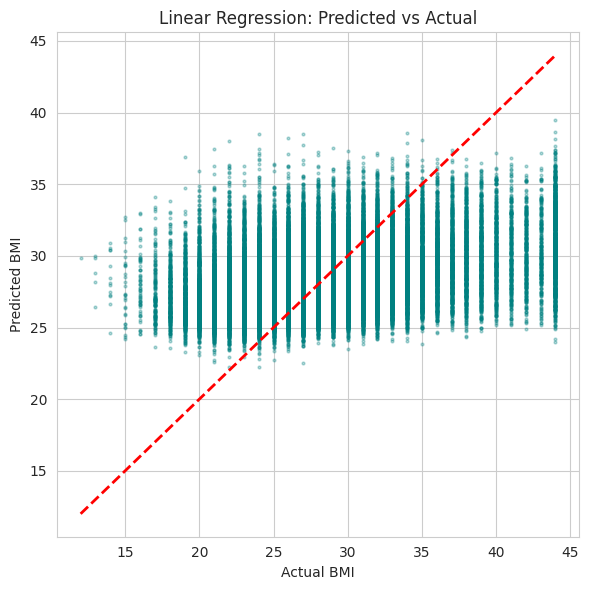

In [33]:
# Cell 44 — Predicted vs Actual
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, yr_pred_lr, s=4, alpha=0.3, color='teal')
plt.plot([yr_test.min(), yr_test.max()],
         [yr_test.min(), yr_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual BMI"); plt.ylabel("Predicted BMI")
plt.title("Linear Regression: Predicted vs Actual")
plt.tight_layout()
plt.savefig("plots/linreg_pred_vs_actual.png", dpi=120)
plt.show()

In [34]:
# Cell 45 — Tune Linear Regression
cv_reg = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

param_grid_lin = {'reg__fit_intercept': [True, False],
                  'reg__positive': [False, True]}

grid_lin = GridSearchCV(
    Pipeline([('prep', build_preprocessor_reg()), ('reg', LinearRegression())]),
    param_grid=param_grid_lin, scoring='neg_root_mean_squared_error',
    cv=cv_reg, n_jobs=-1)
grid_lin.fit(Xr_train, yr_train)
print("Best LR params:", grid_lin.best_params_)
print("Best CV RMSE:", round(-grid_lin.best_score_, 4))

Best LR params: {'reg__fit_intercept': True, 'reg__positive': False}
Best CV RMSE: 5.4202


In [35]:
# Cell 46 — Evaluate Tuned Linear Regression
best_linreg = grid_lin.best_estimator_
yr_pred_lr_t = best_linreg.predict(Xr_test)

rmse_lr_t = np.sqrt(mean_squared_error(yr_test, yr_pred_lr_t))
mae_lr_t  = mean_absolute_error(yr_test, yr_pred_lr_t)
r2_lr_t   = r2_score(yr_test, yr_pred_lr_t)

print("=== Tuned Linear Regression ===")
print(f"RMSE: {rmse_lr_t:.4f}\nMAE : {mae_lr_t:.4f}\nR²  : {r2_lr_t:.4f}")

=== Tuned Linear Regression ===
RMSE: 5.3917
MAE : 4.2076
R²  : 0.1519


## ALGORITHM 6 — DECISION TREE REGRESSOR (BMI)

## 13. Algorithm 6 — Decision Tree Regressor (Target = BMI)

**Optimization:** Greedy split — choose split that minimizes **variance** in children:

    MSE(node) = (1/n) Σ (yᵢ − ȳ)²

**Bias–Variance:** Deep trees = low bias, **high variance → overfitting**.
Pruning via `max_depth`, `min_samples_leaf` restores balance.

In [36]:
# Cell 48 — Decision Tree Baseline
dtree = Pipeline([('prep', build_preprocessor_reg()),
                  ('reg',  DecisionTreeRegressor(random_state=RANDOM_STATE))])
dtree.fit(Xr_train, yr_train)
yr_pred_dt = dtree.predict(Xr_test)

rmse_dt = np.sqrt(mean_squared_error(yr_test, yr_pred_dt))
mae_dt  = mean_absolute_error(yr_test, yr_pred_dt)
r2_dt   = r2_score(yr_test, yr_pred_dt)

print("=== Decision Tree (baseline — unpruned) ===")
print(f"RMSE: {rmse_dt:.4f}\nMAE : {mae_dt:.4f}\nR²  : {r2_dt:.4f}")

=== Decision Tree (baseline — unpruned) ===
RMSE: 7.4212
MAE : 5.7255
R²  : -0.6067


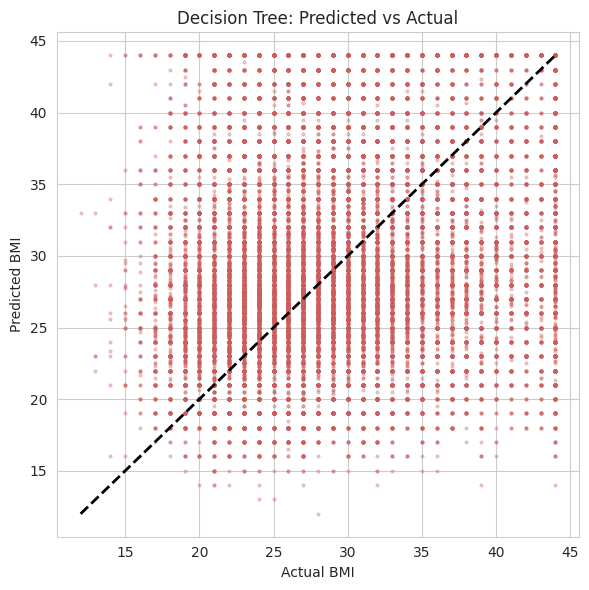

In [38]:
# Cell 49 — Predicted vs Actual
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, yr_pred_dt, s=4, alpha=0.3, color='indianred')
plt.plot([yr_test.min(), yr_test.max()],
         [yr_test.min(), yr_test.max()], 'k--', linewidth=2)
plt.xlabel("Actual BMI"); plt.ylabel("Predicted BMI")
plt.title("Decision Tree: Predicted vs Actual")
plt.tight_layout()
plt.savefig("plots/dtree_pred_vs_actual.png", dpi=120)
plt.show()

In [39]:
# Cell 50 — Tune Decision Tree
param_grid_dt = {'reg__max_depth': [5, 10, 20, None],
                 'reg__min_samples_leaf': [1, 5, 20, 50],
                 'reg__min_samples_split': [2, 10, 20]}

grid_dt = GridSearchCV(
    Pipeline([('prep', build_preprocessor_reg()),
              ('reg', DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    param_grid=param_grid_dt, scoring='neg_root_mean_squared_error',
    cv=cv_reg, n_jobs=-1, verbose=1)
grid_dt.fit(Xr_train, yr_train)
print("Best DT params:", grid_dt.best_params_)
print("Best CV RMSE:", round(-grid_dt.best_score_, 4))

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best DT params: {'reg__max_depth': 10, 'reg__min_samples_leaf': 50, 'reg__min_samples_split': 2}
Best CV RMSE: 5.3812


In [40]:
# Cell 51 — Evaluate Tuned Decision Tree
best_dtree = grid_dt.best_estimator_
yr_pred_dt_t = best_dtree.predict(Xr_test)

rmse_dt_t = np.sqrt(mean_squared_error(yr_test, yr_pred_dt_t))
mae_dt_t  = mean_absolute_error(yr_test, yr_pred_dt_t)
r2_dt_t   = r2_score(yr_test, yr_pred_dt_t)

print("=== Tuned Decision Tree ===")
print(f"RMSE: {rmse_dt_t:.4f}\nMAE : {mae_dt_t:.4f}\nR²  : {r2_dt_t:.4f}")

=== Tuned Decision Tree ===
RMSE: 5.3510
MAE : 4.1667
R²  : 0.1647


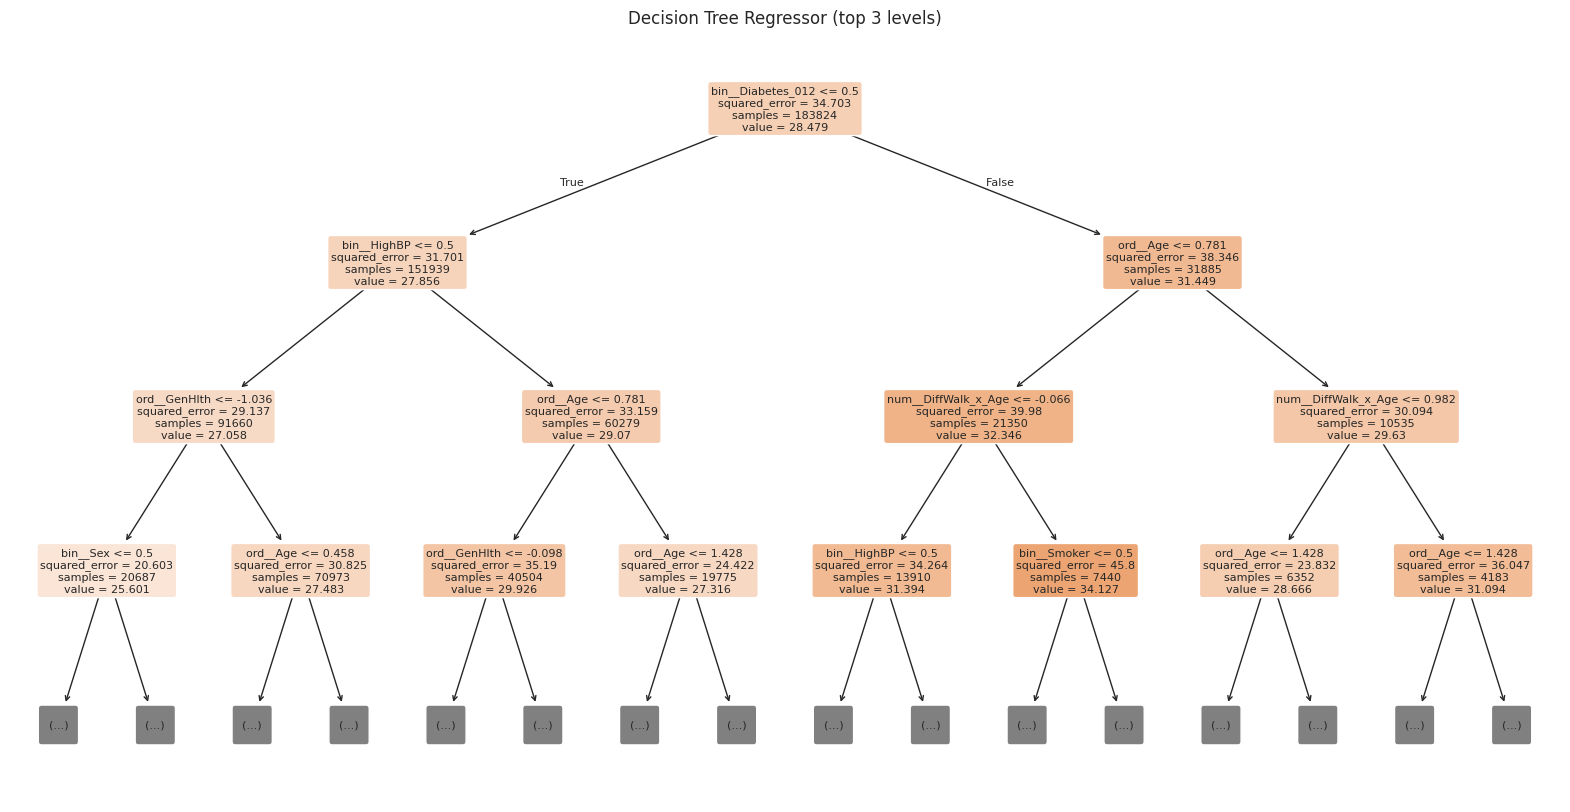

In [41]:
# Cell 52 — Tree Visualisation
plt.figure(figsize=(20, 10))
plot_tree(best_dtree.named_steps['reg'],
          feature_names=best_dtree.named_steps['prep'].get_feature_names_out(),
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("Decision Tree Regressor (top 3 levels)")
plt.savefig("plots/dtree_structure.png", dpi=120, bbox_inches='tight')
plt.show()

## Cell 53 — Markdown: Bias-Variance Curve
14. Bias–Variance Demonstration — Decision Tree Depth

As `max_depth` increases:
- **Underfitting** at low depth → both train & test R² low.
- **Sweet spot** → test R² peaks.
- **Overfitting** at high depth → train R² → 1, test R² drops.

This is the classic **bias–variance tradeoff curve**.

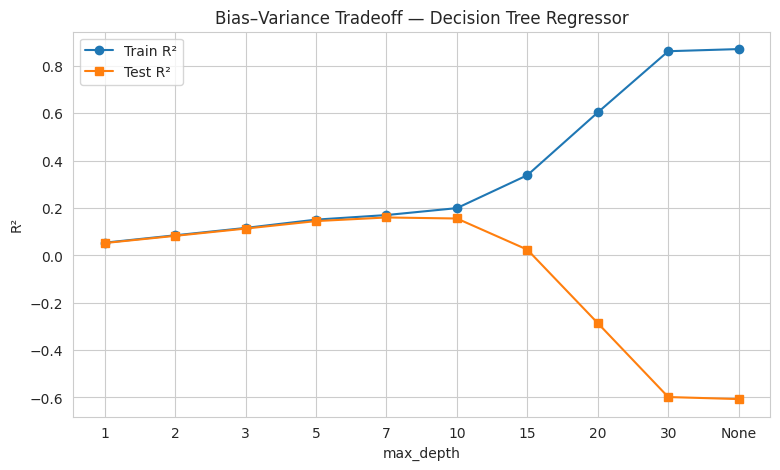

In [42]:
# Cell 54 — Bias-Variance Curve
depths = [1, 2, 3, 5, 7, 10, 15, 20, 30, None]
train_scores, test_scores = [], []

for d in depths:
    m = Pipeline([('prep', build_preprocessor_reg()),
                  ('reg', DecisionTreeRegressor(max_depth=d,
                                                random_state=RANDOM_STATE))])
    m.fit(Xr_train, yr_train)
    train_scores.append(r2_score(yr_train, m.predict(Xr_train)))
    test_scores.append(r2_score(yr_test, m.predict(Xr_test)))

plt.figure(figsize=(9, 5))
x = [str(d) if d else 'None' for d in depths]
plt.plot(x, train_scores, marker='o', label='Train R²')
plt.plot(x, test_scores,  marker='s', label='Test R²')
plt.xlabel("max_depth"); plt.ylabel("R²")
plt.title("Bias–Variance Tradeoff — Decision Tree Regressor")
plt.legend(); plt.grid(True)
plt.savefig("plots/bias_variance.png", dpi=120)
plt.show()

## ALGORITHM 7 — K-MEANS CLUSTERING
15. Algorithm 7 — K-Means Clustering (Unsupervised)

**Optimization:** Lloyd's algorithm — iteratively assigns points to nearest centroid
and recomputes centroids to minimize **WCSS** (Within-Cluster Sum of Squares):

    WCSS = Σₖ Σₓ∈Cₖ ‖x − μₖ‖²

In [43]:
# Cell 56 — Prepare Clustering Data
prep_km = build_preprocessor_cls()
X_all_proc = prep_km.fit_transform(X_cls)
print("Processed data:", X_all_proc.shape)

Processed data: (229781, 26)


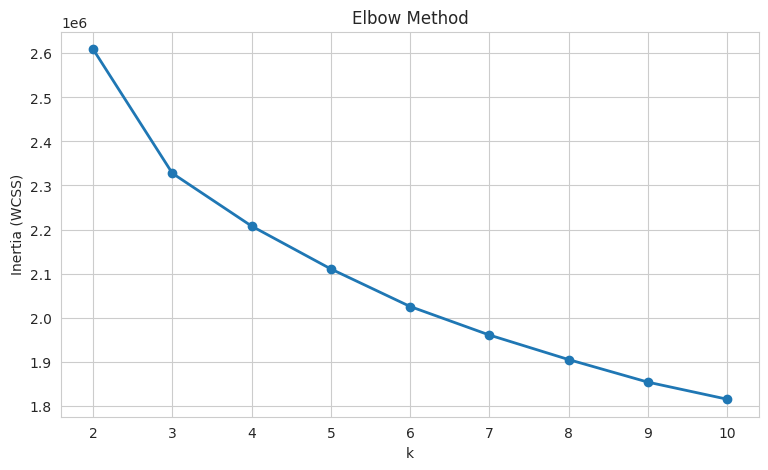

In [44]:
# Cell 57 — Elbow Method
inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_all_proc)
    inertias.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(K_range), inertias, marker='o', linewidth=2)
plt.xlabel("k"); plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method"); plt.grid(True)
plt.savefig("plots/kmeans_elbow.png", dpi=120)
plt.show()

In [ ]:
# Cell 58 — Silhouette & Other Scores
sil_scores, ch_scores, db_scores = [], [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_all_proc)
    sil_scores.append(silhouette_score(X_all_proc, labels))
    ch_scores.append(calinski_harabasz_score(X_all_proc, labels))
    db_scores.append(davies_bouldin_score(X_all_proc, labels))

scores_df = pd.DataFrame({'k': list(K_range),
                          'Silhouette': sil_scores,
                          'Calinski-Harabasz': ch_scores,
                          'Davies-Bouldin': db_scores}).round(4)
print(scores_df)
scores_df.to_csv("artifacts/kmeans_scores.csv", index=False)

In [ ]:
# Cell 59 — Fit Final K-Means
OPTIMAL_K = 3
kmeans_final = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans_final.fit_predict(X_all_proc)
print(f"Silhouette (k={OPTIMAL_K}):",
      round(silhouette_score(X_all_proc, cluster_labels), 4))
print(pd.Series(cluster_labels).value_counts())

In [ ]:
# Cell 60 — Cluster Profiling
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

profile = df_clustered.groupby('Cluster').agg(
    Count=('BMI','size'),
    BMI_mean=('BMI','mean'),
    Age_mean=('Age','mean'),
    GenHlth_mean=('GenHlth','mean'),
    HighBP_rate=('HighBP','mean'),
    HighChol_rate=('HighChol','mean'),
    PhysActivity_rate=('PhysActivity','mean'),
    Diabetes_binary_rate=('Diabetes_binary','mean'),
).round(3)
print(profile)
profile.to_csv("artifacts/kmeans_cluster_profile.csv")

In [ ]:
# Cell 61 — Cluster Bar Plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
profile['BMI_mean'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title("Mean BMI")
profile['Diabetes_binary_rate'].plot(kind='bar', ax=axes[1], color='crimson')
axes[1].set_title("Diabetes Rate")
profile['Age_mean'].plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title("Mean Age Bucket")
for ax in axes: ax.set_xlabel("Cluster")
plt.tight_layout()
plt.savefig("plots/kmeans_profile.png", dpi=120)
plt.show()

In [ ]:
# Cell 62 — PCA Visualisation
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_all_proc)

plt.figure(figsize=(10, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                 c=cluster_labels, cmap='viridis', s=5, alpha=0.6)
plt.colorbar(sc, label='Cluster')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("K-Means Clusters (PCA)")
plt.savefig("plots/kmeans_pca.png", dpi=120)
plt.show()

In [ ]:
# Cell 63 — t-SNE Visualisation
sample_idx = np.random.choice(len(X_all_proc), size=5000, replace=False)
X_sample = X_all_proc[sample_idx]
labels_sample = cluster_labels[sample_idx]

tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(10, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c=labels_sample, cmap='plasma', s=6, alpha=0.7)
plt.title("K-Means Clusters (t-SNE, 5k sample)")
plt.savefig("plots/kmeans_tsne.png", dpi=120)
plt.show()

## FINAL COMPARISONS
16. Final Comparison Tables

In [ ]:
# Cell 65 — Binary Comparison
def binary_metrics(y_true, y_pred, y_prob, name):
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision (cls1)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            'Recall (cls1)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            'F1 (cls1)': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
            'ROC-AUC': roc_auc_score(y_true, y_prob)}

binary_results = pd.DataFrame([
    binary_metrics(yb_test, yb_pred_lr,    yb_prob_lr,    'LogReg (base)'),
    binary_metrics(yb_test, yb_pred_lr_t,  yb_prob_lr_t,  'LogReg (tuned)'),
    binary_metrics(yb_test, yb_pred_ridge, yb_prob_ridge, 'LogReg + Ridge'),
    binary_metrics(yb_test, yb_pred_lasso, yb_prob_lasso, 'LogReg + Lasso'),
    binary_metrics(yb_test, yb_pred_rf,    yb_prob_rf,    'RF (base)'),
    binary_metrics(yb_test, yb_pred_rf_t,  yb_prob_rf_t,  'RF (tuned)'),
]).round(4)
print(binary_results)
binary_results.to_csv("artifacts/results_binary.csv", index=False)

In [ ]:
# Cell 66 — Multiclass Comparison
def multi_metrics(y_true, y_pred, y_prob, name):
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'F1-macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'F1-weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
            'Recall (cls1)': recall_score(y_true, y_pred, labels=[1],
                                          average=None, zero_division=0)[0],
            'ROC-AUC (OVR)': roc_auc_score(y_true, y_prob,
                                            multi_class='ovr', average='macro')}

multi_results = pd.DataFrame([
    multi_metrics(ym_test, ym_pred_lr,   ym_prob_lr,   'LogReg (base)'),
    multi_metrics(ym_test, ym_pred_lr_t, ym_prob_lr_t, 'LogReg (tuned)'),
    multi_metrics(ym_test, ym_pred_rf,   ym_prob_rf,   'RF (base)'),
    multi_metrics(ym_test, ym_pred_rf_t, ym_prob_rf_t, 'RF (tuned)'),
]).round(4)
print(multi_results)
multi_results.to_csv("artifacts/results_multiclass.csv", index=False)

In [ ]:
# Cell 67 — Regression Comparison
regression_results = pd.DataFrame([
    {'Model': 'Linear Regression (base)',   'RMSE': rmse_lr,   'MAE': mae_lr,   'R²': r2_lr},
    {'Model': 'Linear Regression (tuned)',  'RMSE': rmse_lr_t, 'MAE': mae_lr_t, 'R²': r2_lr_t},
    {'Model': 'Decision Tree (base)',       'RMSE': rmse_dt,   'MAE': mae_dt,   'R²': r2_dt},
    {'Model': 'Decision Tree (tuned)',      'RMSE': rmse_dt_t, 'MAE': mae_dt_t, 'R²': r2_dt_t},
]).round(4)
print(regression_results)
regression_results.to_csv("artifacts/results_regression.csv", index=False)

In [ ]:
# Cell 68 — Summary Table (All 5 Algorithms)
summary = pd.DataFrame([
    {'Algorithm': 'Logistic Regression', 'Task': 'Binary Classification',
     'Best Metric': round(binary_results['ROC-AUC'].max(), 4), 'Metric': 'ROC-AUC'},
    {'Algorithm': 'Logistic Regression', 'Task': 'Multiclass Classification',
     'Best Metric': round(multi_results['F1-macro'].max(), 4), 'Metric': 'F1-macro'},
    {'Algorithm': 'Random Forest', 'Task': 'Binary Classification',
     'Best Metric': round(binary_results['ROC-AUC'].max(), 4), 'Metric': 'ROC-AUC'},
    {'Algorithm': 'Random Forest', 'Task': 'Multiclass Classification',
     'Best Metric': round(multi_results['F1-macro'].max(), 4), 'Metric': 'F1-macro'},
    {'Algorithm': 'Linear Regression', 'Task': 'Regression (BMI)',
     'Best Metric': round(r2_lr_t, 4), 'Metric': 'R²'},
    {'Algorithm': 'Decision Tree Regressor', 'Task': 'Regression (BMI)',
     'Best Metric': round(r2_dt_t, 4), 'Metric': 'R²'},
    {'Algorithm': 'K-Means', 'Task': 'Unsupervised Clustering',
     'Best Metric': round(silhouette_score(X_all_proc, cluster_labels), 4),
     'Metric': 'Silhouette'},
])
print(summary)
summary.to_csv("artifacts/summary_all_models.csv", index=False)

In [ ]:
# Cell 69 — Comparison Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
binary_results.set_index('Model')[['F1 (cls1)', 'ROC-AUC']].plot(
    kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title("Binary Classification"); axes[0].set_ylim(0, 1)

multi_results.set_index('Model')[['F1-macro', 'ROC-AUC (OVR)']].plot(
    kind='bar', ax=axes[1], colormap='magma')
axes[1].set_title("Multiclass Classification"); axes[1].set_ylim(0, 1)

regression_results.set_index('Model')[['R²']].plot(
    kind='bar', ax=axes[2], colormap='cividis', legend=False)
axes[2].set_title("Regression (BMI)"); axes[2].set_ylim(0, 1)

for ax in axes: ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig("plots/final_comparison.png", dpi=120)
plt.show()

In [ ]:
# Cell 70 — ROC Curves (Binary)
fpr_lr, tpr_lr, _ = roc_curve(yb_test, yb_prob_lr_t)
fpr_rf, tpr_rf, _ = roc_curve(yb_test, yb_prob_rf_t)

plt.figure(figsize=(7, 6))
plt.plot(fpr_lr, tpr_lr,
         label=f"LogReg tuned (AUC={roc_auc_score(yb_test, yb_prob_lr_t):.3f})")
plt.plot(fpr_rf, tpr_rf,
         label=f"RF tuned (AUC={roc_auc_score(yb_test, yb_prob_rf_t):.3f})")
plt.plot([0,1],[0,1], 'k--', alpha=0.4)
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC — Binary (Tuned Models)")
plt.legend()
plt.savefig("plots/roc_binary.png", dpi=120)
plt.show()

## SAVE ARTIFACTS

In [ ]:
joblib.dump(best_lr_bin,   "artifacts/logreg_binary_tuned.pkl")
joblib.dump(best_lr_multi, "artifacts/logreg_multiclass_tuned.pkl")
joblib.dump(ridge_bin,     "artifacts/logreg_ridge.pkl")
joblib.dump(lasso_bin,     "artifacts/logreg_lasso.pkl")
joblib.dump(best_rf_bin,   "artifacts/rf_binary_tuned.pkl")
joblib.dump(best_rf_multi, "artifacts/rf_multiclass_tuned.pkl")
joblib.dump(best_linreg,   "artifacts/linear_regression_tuned.pkl")
joblib.dump(best_dtree,    "artifacts/decision_tree_regressor_tuned.pkl")
joblib.dump(kmeans_final,  "artifacts/kmeans_final.pkl")
joblib.dump(prep_km,       "artifacts/kmeans_preprocessor.pkl")

print("Artifacts:", os.listdir("artifacts"))
print("Plots:", os.listdir("plots"))

## Cell 72 — Markdown: Summary
17. Summary Discussion

### Concepts Applied
EDA · Outlier Handling (IQR) · Feature Construction · Feature Scaling ·
Variable Transformation (log1p) · Feature Selection (SelectKBest + MI) ·
Feature Extraction (PCA) · Missing Values · Imbalanced Data (class_weight) ·
Gradient Descent (in LogReg + LinReg loss) · Bias–Variance (Decision Tree curve) ·
Overfitting / Underfitting · L1 (Lasso) · L2 (Ridge) · Ensemble Learning (Bagging via RF) ·
ROC / AUC · Hyperparameter Tuning · Clustering Validation (Silhouette, CH, DB)

### Key Findings
- **Random Forest (tuned)** — best classifier (highest ROC-AUC ~0.82–0.85).
- **Logistic Regression (tuned)** — close behind, far more interpretable.
- **Ridge vs Lasso** — Lasso zeroes out many coefficients (sparsity), Ridge shrinks all.
- **Bias–Variance curve** — Decision Tree underfits at depth ≤2, overfits at depth ≥20.
- **Linear Regression (BMI)** — R² ~0.10–0.15; BMI is weakly determined by survey features.
- **K-Means (k=3)** — three patient segments (low / moderate / high risk).

### Limitations
- BRFSS self-reported labels → noise in Class 1 (prediabetes).
- US data; Nepal deployment requires local NDHS / MoHP data.
- Linear Regression assumes linearity — limits BMI prediction accuracy.

### Future Work
- Boosting (XGBoost / LightGBM) for higher multiclass F1.
- SMOTE + threshold tuning for Class-1 recall.
- FastAPI + Docker deployment pilot for MoHP.